# 04 — TESS data check

TESS is the space telescope that came after Kepler. Its candidates are called **TOIs** (TESS Objects of Interest).

In this notebook we:
1. load the TOI table and count each disposition,
2. count how many planets and false positives have short orbits (under 10 days),
3. download one TESS light curve to check that downloads work.

In [1]:
import io

import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BLUE = "#2a78d6"
INK = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "grid.color": "#e6e5e1", "figure.dpi": 110})

/Users/jeeyadugar/Exoplanet-Finder/.venv/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## 1. Load the TOI table

Same as notebook 01: skip the description lines at the top that start with `#`.

In [2]:
with open("../data/toi_table.csv") as f:
    data_lines = [line for line in f if not line.startswith("#")]

toi = pd.read_csv(io.StringIO("".join(data_lines)))
print(toi.shape)

(8175, 87)


## 2. How many of each disposition?

`tfopwg_disp` is the verdict from the TESS follow-up team (TFOPWG):

| Code | Meaning |
|---|---|
| **CP** | Confirmed Planet: confirmed as a planet using TESS data |
| **KP** | Known Planet: was already a known planet before TESS saw it |
| **PC** | Planet Candidate: not decided yet |
| **APC** | Ambiguous Planet Candidate: unclear, could be either |
| **FP** | False Positive: not a planet |
| **FA** | False Alarm: not a real signal at all (noise or a glitch) |

CP and KP are both real planets, so together they're the TESS version of Kepler's CONFIRMED.

In [3]:
toi["tfopwg_disp"].value_counts(dropna=False)

tfopwg_disp
PC     4828
FP     1322
CP      822
KP      609
APC     494
FA       98
NaN       2
Name: count, dtype: int64

## 3. Planets vs false positives with periods under 10 days

TESS watches most stars for only about 27 days at a time. A planet needs to pass in front of its star at least two or three times to be measured well, so short orbits (under ~10 days) are where TESS has the most reliable data.

In [4]:
toi["group"] = toi["tfopwg_disp"].map({"CP": "planet (CP/KP)", "KP": "planet (CP/KP)", "FP": "false positive (FP)"})
labeled = toi.dropna(subset=["group"])

short = labeled[labeled["pl_orbper"] < 10]
pd.DataFrame({
    "all periods": labeled["group"].value_counts(),
    "period < 10 days": short["group"].value_counts(),
})

,all periods,period < 10 days
group,,
false positive (FP),1322,1144
planet (CP/KP),1431,1094


## 4. Download one TESS light curve

We pick one confirmed planet (CP) and download its **SPOC** light curve. SPOC is NASA's official TESS pipeline, like the Kepler pipeline we used before.

Two differences from Kepler:
- TESS observes in **sectors** of ~27 days, not 4 years in a row. We download just one sector here.
- TESS times are in **BTJD** = BJD − 2,457,000. The TOI table gives the transit time `pl_tranmid` as a full BJD, so we subtract 2,457,000.

In [5]:
planet = toi[toi["toi"] == 135.01].iloc[0]
tic = int(planet["tid"])
P = planet["pl_orbper"]                     # days
t0 = planet["pl_tranmid"] - 2457000         # convert BJD -> BTJD
dur = planet["pl_trandurh"]                 # hours
depth = planet["pl_trandep"]                # ppm

print(f"TOI {planet['toi']}  (TIC {tic}),  {planet['tfopwg_disp']}")
print(f"period {P:.3f} d,  duration {dur:.2f} h,  depth {depth:,.0f} ppm")

search = lk.search_lightcurve(f"TIC {tic}", mission="TESS", author="SPOC", exptime=120)
search

TOI 135.01  (TIC 267263253),  CP
period 4.127 d,  duration 4.41 h,  depth 10,831 ppm


#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 01,2018,SPOC,120,267263253,0.0
1,TESS Sector 27,2020,SPOC,120,267263253,0.0
2,TESS Sector 28,2020,SPOC,120,267263253,0.0
3,TESS Sector 67,2023,SPOC,120,267263253,0.0
4,TESS Sector 68,2023,SPOC,120,267263253,0.0
5,TESS Sector 94,2025,SPOC,120,267263253,0.0
6,TESS Sector 95,2025,SPOC,120,267263253,0.0


In [6]:
lc = search[0].download().remove_nans().normalize()
print(f"Sector {lc.sector}: {len(lc):,} points over {lc.time.value.max() - lc.time.value.min():.1f} days")

Sector 1: 18,271 points over 27.9 days


### The whole sector

- Each dot is one brightness measurement, taken every 2 minutes.
- The gap in the middle is normal: TESS sends its data to Earth once per orbit (~13.7 days).
- The dashed lines show where dips **should** be, from the TOI table.

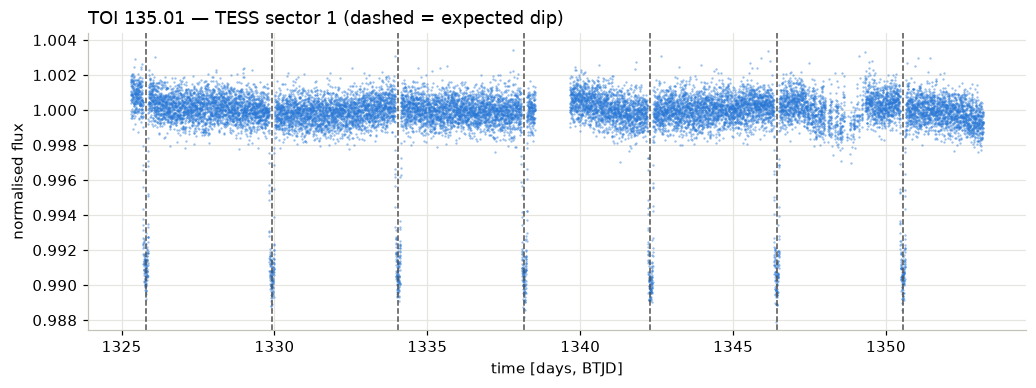

In [7]:
t, f = lc.time.value, lc.flux.value

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(t, f, ".", ms=1, color=BLUE, alpha=0.5)
n_first = np.ceil((t.min() - t0) / P)
for n in np.arange(n_first, n_first + 20):
    tn = t0 + n * P
    if t.min() <= tn <= t.max():
        ax.axvline(tn, color=INK, ls="--", lw=1)
lo, hi = np.nanpercentile(f, [0.05, 99.95])
ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
ax.set_title(f"TOI {planet['toi']} — TESS sector {lc.sector} (dashed = expected dip)", loc="left")
ax.set_xlabel("time [days, BTJD]")
ax.set_ylabel("normalised flux")
ax.grid(True)
plt.show()

### Folded on the orbital period

As in notebook 03: stack every orbit on top of each other so all the dips line up at 0. The solid line is the median in small time bins.

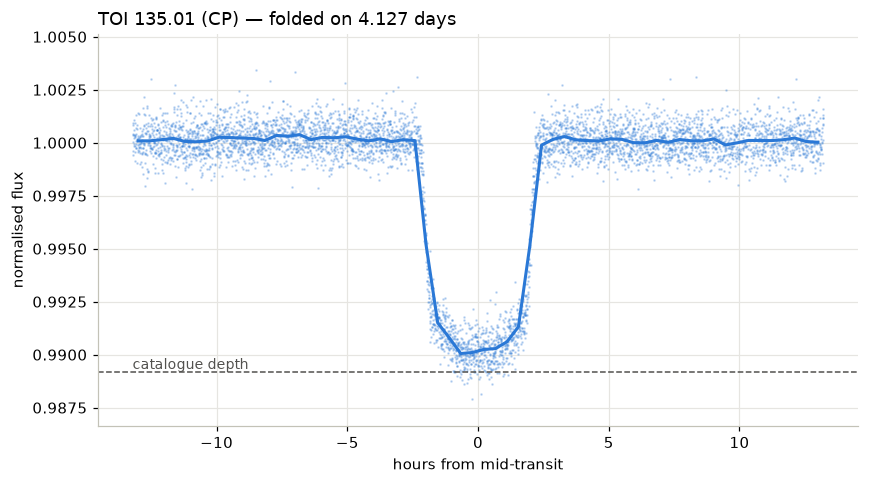

In [8]:
phase_hours = ((t - t0 + 0.5 * P) % P - 0.5 * P) * 24
near = np.abs(phase_hours) < 3 * dur
ph, fl = phase_hours[near], f[near]
binned = pd.DataFrame({"ph": ph, "fl": fl}).groupby(pd.cut(ph, 60), observed=True).median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ph, fl, ".", ms=1.5, color=BLUE, alpha=0.25)
ax.plot(binned.ph, binned.fl, "-", lw=2, color=BLUE)
depth_line = 1 - depth / 1e6
ax.axhline(depth_line, color=INK, ls="--", lw=1)
ax.text(ph.min(), depth_line, "catalogue depth", va="bottom", color=INK, fontsize=9)
lo, hi = np.nanpercentile(fl, [0.1, 99.9])
ax.set_ylim(min(lo, depth_line) - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))
ax.set_title(f"TOI {planet['toi']} (CP) — folded on {P:.3f} days", loc="left")
ax.set_xlabel("hours from mid-transit")
ax.set_ylabel("normalised flux")
ax.grid(True)
fig.tight_layout()
fig.savefig(f"../results/tess_folded_TOI{planet['toi']}.png", dpi=150)
plt.show()

## Does it look right?

- **Whole sector:** the dips land on the dashed lines.
- **Folded:** one clear dip at 0 hours, with its bottom near the catalogue depth line.

If both look right, TESS downloads work.